# 2. Cleaning, Target and Features

1. Keep only comparable videos
2. Define the target: **did a video beat its channel's typical views?**
3. Build features that are known **at upload time**
4. Explore the data

## Setup

In [1]:
import pandas as pd
import numpy as np
import isodate
import matplotlib.pyplot as plt

videos = pd.read_csv("videos_raw.csv")
videos["published_at"] = pd.to_datetime(videos["published_at"])
videos["duration_sec"] = videos["duration"].apply(lambda d: isodate.parse_duration(d).total_seconds())   # "PT12M34S" -> 754
print(videos.shape)
videos[["title", "published_at", "duration_sec", "views"]].head()

(8574, 13)


,title,published_at,duration_sec,views
0,"MUKBANG WITH BFF AND BRO🔥😋 SPICY ALOO BIRYANI,...",2026-10-03 09:01:19+00:00,868.0,87472
1,"VIRAL SPICY CHEESY BULDAK NOODLES ONION WRAP, ...",2026-09-30 09:38:51+00:00,977.0,252525
2,"CHICKEN BIRYANI, PANEER BIRYANI AND SPICY NARG...",2026-09-26 09:59:56+00:00,968.0,248429
3,"SPICY CHICKEN CHOPPER FRIED RICE, JAPANESE FLU...",2026-09-23 09:47:22+00:00,1011.0,367851
4,"CHICKEN LOLLIPOP BIRYANI, SPICY CHICKEN GRAVY ...",2026-09-18 10:47:06+00:00,1014.0,368597


## 1. Keep comparable videos

- **Under 30 days old:** views are still growing, so they aren't comparable yet
- **Over 2 years old:** a different era of the YouTube algorithm
- **Shorts (≤ 3 min):** a different format and feed
- **Livestreams / premieres:** different viewing behavior

In [2]:
now = videos["published_at"].max()
videos["age_days"] = (now - videos["published_at"]).dt.days

print("Before:", len(videos))
videos = videos[videos["age_days"].between(30, 730)]
videos = videos[videos["duration_sec"] > 180]
videos = videos[videos["live"] == "none"]
print("After: ", len(videos))

Before: 8574
After:  4260


## 2. Target: did the video beat its channel's typical views?

Predicting raw views would just teach the model that big channels get more views. Instead each video is compared with **its own channel**.

**First attempt:** `popular = views > the channel's median views`. This has a problem: older videos have had more time to collect views,
so they are labeled "popular" much more often:

In [3]:
age_bucket = pd.cut(videos["age_days"], [29, 90, 180, 365, 731], labels=["30-90 days", "90-180 days", "180-365 days", "1-2 years"])
first_attempt = videos["views"] > videos.groupby("channel_id")["views"].transform("median")
first_attempt.groupby(age_bucket, observed=True).mean().round(3).rename("popular rate")

age_days
30-90 days      0.464
90-180 days     0.379
180-365 days    0.480
1-2 years       0.610
Name: popular rate, dtype: float64

**Fix:** compare each video only with the **same channel's videos from the same quarter** (3-month period).
Videos from the same period are about the same age, so age no longer decides the label.
It also means a video is never compared with videos from the future.

Channels with fewer than 30 videos, and channel-quarters with fewer than 5 videos, are dropped: a median of 1–4 videos isn't meaningful.

In [4]:
videos["quarter"] = videos["published_at"].dt.tz_localize(None).dt.to_period("Q").astype(str)

videos = videos[videos.groupby("channel_id")["video_id"].transform("size") >= 30]
videos = videos[videos.groupby(["channel_id", "quarter"])["video_id"].transform("size") >= 5]

quarter_median = videos.groupby(["channel_id", "quarter"])["views"].transform("median")
videos["popular"] = (videos["views"] > quarter_median).astype(int)

age_bucket = pd.cut(videos["age_days"], [29, 90, 180, 365, 731], labels=["30-90 days", "90-180 days", "180-365 days", "1-2 years"])
print(len(videos), "videos from", videos["channel_id"].nunique(), "channels")
videos["popular"].groupby(age_bucket, observed=True).mean().round(3).rename("popular rate")

4221 videos from 27 channels


age_days
30-90 days      0.491
90-180 days     0.492
180-365 days    0.491
1-2 years       0.493
Name: popular rate, dtype: float64

Now every age group is ~49% popular: the label measures popularity, not age.

## 3. Features (known at upload time)

**Rule:** only information a creator has at the moment of upload. Likes, comments and views happen afterwards, so they are never features.

Times are converted from UTC to Indian time (IST), since these are Indian channels.

In [5]:
title = videos["title"]
videos["title_length"] = title.str.len()
videos["title_words"] = title.str.split().str.len()
videos["title_caps_ratio"] = title.apply(lambda t: sum(c.isupper() for c in t) / max(len(t), 1))
videos["title_has_number"] = title.str.contains(r"\d").astype(int)
videos["title_has_question"] = title.str.contains(r"\?").astype(int)
videos["title_has_exclaim"] = title.str.contains("!").astype(int)
videos["title_has_emoji"] = title.apply(lambda t: any(ord(c) > 10000 for c in t)).astype(int)

In [6]:
ist = videos["published_at"].dt.tz_convert("Asia/Kolkata")
videos["publish_hour"] = ist.dt.hour
videos["publish_weekday"] = ist.dt.dayofweek          # 0 = Monday

videos["duration_min"] = videos["duration_sec"] / 60
videos["num_tags"] = videos["tags"].fillna("").apply(lambda t: len(t.split("|")) if t else 0)
videos["description_length"] = videos["description"].fillna("").str.len()
videos["description_links"] = videos["description"].fillna("").str.count("http")

# Days since the channel's previous (long-form) video
videos = videos.sort_values(["channel_id", "published_at"])
gap = videos.groupby("channel_id")["published_at"].diff().dt.days
videos["days_since_last_upload"] = gap.fillna(gap.median())

## 4. Explore

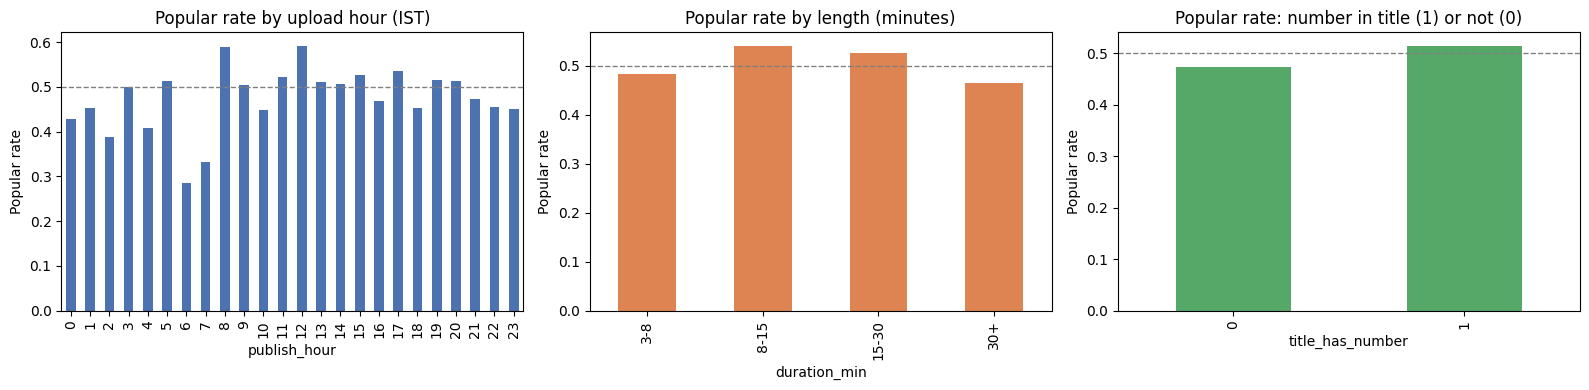

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

videos.groupby("publish_hour")["popular"].mean().plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set_title("Popular rate by upload hour (IST)")

duration_bucket = pd.cut(videos["duration_min"], [3, 8, 15, 30, 600], labels=["3-8", "8-15", "15-30", "30+"])
videos.groupby(duration_bucket, observed=True)["popular"].mean().plot.bar(ax=axes[1], color="#DD8452")
axes[1].set_title("Popular rate by length (minutes)")

videos.groupby("title_has_number")["popular"].mean().plot.bar(ax=axes[2], color="#55A868")
axes[2].set_title("Popular rate: number in title (1) or not (0)")

for ax in axes:
    ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
    ax.set_ylabel("Popular rate")
plt.tight_layout()
plt.show()

**What the charts show** (dashed line = 50%, the average):

- **Upload hour:** videos uploaded between 2 and 7 AM IST beat their channel's median only 44% of the time (351 videos), versus ~50% at other hours.
- **Length:** 8–30 minute videos do slightly better (~53%) than short 3–8 minute videos or 30+ minute videos (~47%).
- **Numbers in the title** ("Top 10…", "₹500 vs ₹5000"): 51.5% popular vs 47.2% without.

Every effect is only a few percentage points. Metadata gives hints, but most of a video's success comes from things not in this data (thumbnail, topic, trends).

## Save

In [8]:
columns = ["video_id", "channel_id", "title", "tags", "published_at", "quarter", "views", "popular",
           "title_length", "title_words", "title_caps_ratio", "title_has_number", "title_has_question",
           "title_has_exclaim", "title_has_emoji", "duration_min", "publish_hour", "publish_weekday",
           "num_tags", "description_length", "description_links", "days_since_last_upload"]
videos[columns].to_csv("videos_features.csv", index=False)
videos[columns].shape

(4221, 22)